# Defection model

Roadmap step 3, part 3. Which members vote with the other party, on which votes, and how has that changed?

**Unit of analysis:** one Democrat or Republican Yea or Nay on a party-opposed roll call, meaning one where the two party majorities voted on opposite sides. **Defection** means voting with the other party's majority. Votes from 1901 to 2023 are used, and an analysis sample takes up to 15,000 votes per Congress and chamber.

**Member features**, all from Voteview:

- party and region, with the South as the 11 former Confederate states and Border, Northeast, Midwest and West separate;
- tenure (earlier Congresses served in either chamber, linked by Bioguide ID), freshman status and age;
- majority status and party seat share. Independents are counted with the nearer party by DW-NOMINATE, and tied chambers are left missing;
- the member's defection rate in their previous Congress;
- their Nokken-Poole position relative to their party in their previous Congress.

**Roll-call features:** Clausen topic (through 2014), vote type (from 1991) and chamber.

**Not used:**

- the roll call's own margin, because it is computed from the same votes and so partly contains the outcome;
- district presidential vote and electoral margins, which aren't in Voteview. These are likely to matter, so their absence is a real limit.

Odds ratios are associations, not causes. Their intervals are clustered by member and by roll call.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("LOKY_MAX_CPU_COUNT", "8")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

sys.path.append(str(Path.cwd().parent))
sys.path.append(str(Path.cwd().parents[1] / "data_loading"))
from explanation import ROLLCALL_KEYS, defection_rows, first_year, lagged_position, member_covariates
from voteview import load_members, load_rollcalls, load_topics, load_votes

warnings.filterwarnings("ignore")
COLORS = {"D": "#2a78d6", "R": "#c93b3b"}
NEUTRAL = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b4ad",
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e6e5df", "grid.linewidth": 0.8,
    "lines.linewidth": 2, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": "#0b0b0b", "xtick.color": NEUTRAL, "ytick.color": NEUTRAL,
    "legend.frameon": False,
})
INCOMPLETE_CONGRESS = 119
MIN_PARTY_MEMBERS = 10
SAMPLE_PER_CONGRESS = 15000
rng_seed = 0

members = load_members()
members = members[~members["is_delegate"]]
covariates = member_covariates(members)
covariates["lagged_toward_other"] = lagged_position(covariates)
counts = members.groupby(["congress", "chamber"])["party"].value_counts().unstack(fill_value=0)
selected = counts[(counts["D"] >= MIN_PARTY_MEMBERS) & (counts["R"] >= MIN_PARTY_MEMBERS)].index

votes = load_votes()
votes = votes[(votes["congress"] >= 57) & (votes["congress"] < INCOMPLETE_CONGRESS)]
votes = votes.merge(members[["congress", "chamber", "icpsr", "party"]], on=["congress", "chamber", "icpsr"])
rows = defection_rows(votes)
del votes
rows = rows[pd.MultiIndex.from_frame(rows[["congress", "chamber"]]).isin(selected)]

# Each member's defection rate in their previous Congress, same chamber and party (a strong baseline).
person = covariates[["congress", "chamber", "icpsr", "person"]].drop_duplicates(["congress", "chamber", "icpsr"])
rows = rows.merge(person, on=["congress", "chamber", "icpsr"])
history = rows.groupby(["person", "chamber", "party", "congress"])["defected"].agg(["mean", "count"]).reset_index()
history = history[history["count"] >= 20].assign(congress=lambda h: h["congress"] + 1).rename(columns={"mean": "lagged_defection"})
rows = rows.merge(history[["person", "chamber", "party", "congress", "lagged_defection"]], on=["person", "chamber", "party", "congress"], how="left")
print(f"{len(rows):,} member votes on party-opposed roll calls, 1901 to 2023")
print("Overall defection rate:", round(rows["defected"].mean(), 4))

sample = rows.groupby(["congress", "chamber"], group_keys=False).apply(
    lambda g: g.sample(min(len(g), SAMPLE_PER_CONGRESS), random_state=rng_seed))
del rows
features = covariates[["congress", "chamber", "icpsr", "region", "tenure", "freshman", "age", "majority", "party_seat_share", "lagged_toward_other"]]
sample = sample.merge(features.drop_duplicates(["congress", "chamber", "icpsr"]), on=["congress", "chamber", "icpsr"])
topics = load_topics()[ROLLCALL_KEYS + ["clausen", "vote_type"]]
sample = sample.merge(topics, on=ROLLCALL_KEYS)
sample["year"] = first_year(sample["congress"])
sample["party_region"] = sample["party"] + " " + sample["region"]
sample["rollcall_id"] = pd.factorize(sample["congress"].astype(str) + sample["chamber"] + sample["rollnumber"].astype(str))[0]
sample["has_history"] = sample["lagged_defection"].notna()
sample["has_position"] = sample["lagged_toward_other"].notna()
sample["lagged_toward_other_filled"] = sample["lagged_toward_other"].fillna(0)
sample["tied"] = sample["majority"].isna()
sample["defected"] = sample["defected"].astype(int)
print(f"Analysis sample: {len(sample):,} member votes, up to {SAMPLE_PER_CONGRESS:,} per Congress and chamber.")
print("Rates below are sample rates: the cap weights each Congress and chamber more equally than all votes would.")
print(f"Member votes in tied chambers (control set by the Vice President, majority left missing): {sample['tied'].mean():.3%}")


10,031,232 member votes on party-opposed roll calls, 1901 to 2023
Overall defection rate: 0.1287


Analysis sample: 1,734,638 member votes, up to 15,000 per Congress and chamber.
Rates below are sample rates: the cap weights each Congress and chamber more equally than all votes would.
Member votes in tied chambers (control set by the Vice President, majority left missing): 2.209%


10.0 million member votes on party-opposed roll calls from 1901 to 2023, of which 12.9% were defections. The analysis sample has 1.7 million.

Rates quoted below are **sample rates**: the cap of 15,000 per Congress and chamber gives each Congress and chamber more equal weight than all votes would, which up-weights the Senate. 2.2% of sampled votes are in tied chambers.

## Who votes with the other party?

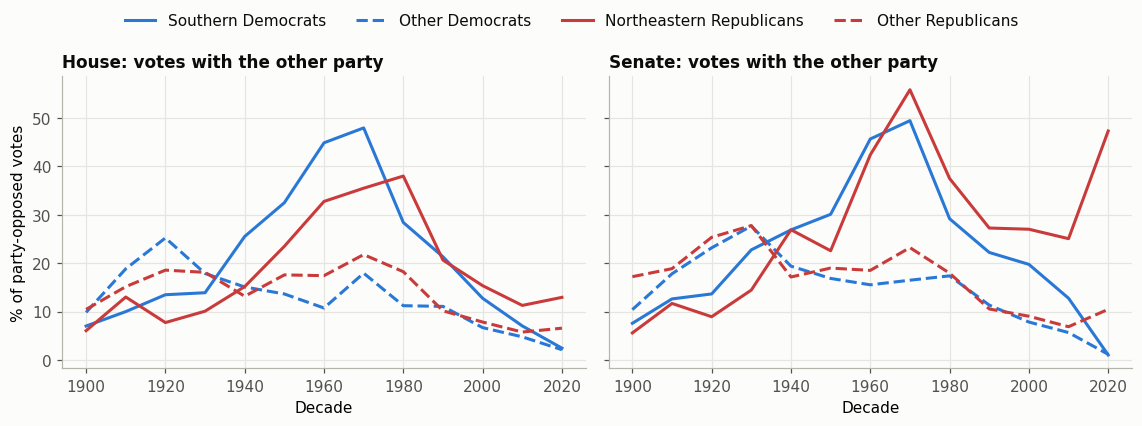

Defection rate, % of party-opposed votes


decade                           1900  1930  1960  1970  1990  2010  2020
House  Southern Democrats         7.0  13.9  44.9  48.0  21.3   7.0   2.4
       Other Democrats            9.8  17.9  10.7  17.9  11.1   4.8   2.1
       Northeastern Republicans   6.1  10.1  32.8  35.5  20.6  11.3  12.9
       Other Republicans         10.5  18.1  17.4  21.8  10.2   5.8   6.6
Senate Southern Democrats         7.6  22.8  45.7  49.5  22.2  12.8   1.0
       Other Democrats           10.4  27.7  15.5  16.5  11.3   5.7   1.2
       Northeastern Republicans   5.6  14.5  42.4  55.9  27.3  25.1  47.3
       Other Republicans         17.2  27.8  18.5  23.2  10.5   6.9  10.5

Number of different members behind each rate


decade                           1900  1930  1960  1970  1990  2010  2020
House  Southern Democrats         161   192   148   138   119    68    60
       Other Democrats            195   381   280   323   302   283   207
       Northeastern Republicans   150   153    89    77    65    49    28
       Other Republicans          269   220   183   187   191   191   129
Senate Southern Democrats          39    40    29    28    22     8     4
       Other Democrats             27    75    63    68    57    68    50
       Northeastern Republicans    27    20    15    15    13     6     2
       Other Republicans           77    43    44    47    50    43    34

'Other Republicans' excludes Southern and Northeastern Republicans; 'Other Democrats' excludes Southern Democrats.


In [2]:
decades = sample.assign(decade=(sample["year"] // 10) * 10)
groups = {"Southern Democrats": ("D", "South"), "Other Democrats": ("D", None), "Northeastern Republicans": ("R", "Northeast"), "Other Republicans": ("R", None)}
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.9), sharey=True)
styles = {"Southern Democrats": (COLORS["D"], "-"), "Other Democrats": (COLORS["D"], "--"),
          "Northeastern Republicans": (COLORS["R"], "-"), "Other Republicans": (COLORS["R"], "--")}
table, people = {}, {}
for axis, chamber in zip(axes, ["House", "Senate"]):
    part = decades[decades["chamber"] == chamber]
    for name, (party, region) in groups.items():
        mask = part["party"] == party
        mask &= (part["region"] == region) if region else ~part["region"].isin(["South", "Northeast"] if party == "R" else ["South"])
        series = part[mask].groupby("decade")["defected"].mean()
        table[(chamber, name)] = series
        people[(chamber, name)] = part[mask].groupby("decade")["person"].nunique()
        color, style = styles[name]
        axis.plot(series.index, series * 100, color=color, linestyle=style, label=name)
    axis.set_title(f"{chamber}: votes with the other party")
    axis.set_xlabel("Decade")
axes[0].set_ylabel("% of party-opposed votes")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4)
fig.tight_layout(rect=(0, 0, 1, 0.92))
plt.show()
DECADES = [1900, 1930, 1960, 1970, 1990, 2010, 2020]
print("Defection rate, % of party-opposed votes")
display((pd.DataFrame(table).T[DECADES] * 100).round(1))
print("Number of different members behind each rate")
display(pd.DataFrame(people).T[DECADES].fillna(0).astype(int))
print("'Other Republicans' excludes Southern and Northeastern Republicans; 'Other Democrats' excludes Southern Democrats.")


**What this shows**

- **Defection rose to a mid-century peak and then collapsed among Southern Democrats.** In the House they voted with Republicans on 45% to 48% of party-opposed votes in the 1960s and 1970s, and on 2.4% in the 2020s. The Senate shows the same pattern.
- **Northeastern Republicans were the matching group,** at 33% to 36% in the House in the 1960s and 1970s, and up to 56% in the Senate. **Unlike Southern Democrats, they still stand out.** In the 2020s House they defect on 12.9% of party-opposed votes (28 members), the highest of any group shown, and up from 11.3% in the 2010s.
- **Other members defected far less at mid-century** (11% to 23%), and their rates also fell.
- **Around 1900, Southern Democrats were less likely than other Democrats to defect** (7.0% against 9.8% in the House). Their mid-century behaviour was a reversal.
- **Watch the member counts.** The Senate's 47% for Northeastern Republicans in the 2020s comes from just 2 senators, and Southern Democrats in the 2020s Senate are 4 senators. Treat those cells as anecdotes.
- These are falls in group averages. They aren't split into members replaced versus members changing; polarization_clustering notebook 04 does that for the overall defection rate.

## What is associated with defection, by era

In [3]:
ERAS = {"1901-1935": (1901, 1935), "1937-1979": (1937, 1979), "1981-2013": (1981, 2013)}
# The roll call's margin isn't used: it is computed from the same votes, so it partly contains the outcome.
FORMULA = ("defected ~ C(party_region, Treatment('D Northeast')) + tenure_5 + freshman + age_10 + majority + chamber"
           " + C(clausen, Treatment('Government Management'))")
def prepare(frame):
    frame = frame[frame["majority"].notna() & ~frame["region"].eq("Other")].copy()
    frame["age"] = frame["age"].fillna(frame["age"].median())
    frame["tenure_5"], frame["age_10"] = frame["tenure"] / 5, frame["age"] / 10
    frame["freshman"], frame["majority"] = frame["freshman"].astype(int), frame["majority"].astype(int)
    return frame


def two_way(frame):
    """Cluster by member and by roll call: topic and vote type are shared by everyone voting on a roll call."""
    return {"groups": np.column_stack([pd.factorize(frame["person"])[0], pd.factorize(frame["rollcall_id"])[0]])}


results = {}
eras_data = {}
for name, (low, high) in ERAS.items():
    era = prepare(sample[sample["year"].between(low, high) & sample["clausen"].notna()])
    era = era.sample(min(len(era), 400000), random_state=rng_seed)
    eras_data[name] = era
    results[name] = smf.logit(FORMULA, data=era).fit(disp=False, cov_type="cluster", cov_kwds=two_way(era))
    print(f"{name}: {len(era):,} votes, {era['person'].nunique():,} members, sample defection rate {era['defected'].mean():.3f}")

def odds_table(results):
    frames = []
    for name, fit in results.items():
        ci = fit.conf_int()
        frames.append(pd.DataFrame({"odds_ratio": np.exp(fit.params), "low": np.exp(ci[0]), "high": np.exp(ci[1])}).add_prefix(f"{name} "))
    table = pd.concat(frames, axis=1).drop(index="Intercept")
    table.index = table.index.str.replace(r"C\((party_region|clausen), Treatment\('[^']*'\)\)\[T\.", "", regex=True).str.rstrip("]")
    return table


odds = odds_table(results)
print("Odds ratios for voting with the other party, with 95% intervals clustered by member and by roll call.")
print("Reference: Northeastern Democrats, Government Management votes, minority party, House.")
display(odds.round(2))

WITHIN = ("defected ~ C(region, Treatment('Midwest')) + tenure_5 + freshman + age_10 + majority + chamber"
          " + C(clausen, Treatment('Government Management'))")
rows = {}
for name, era in eras_data.items():
    for party in ["D", "R"]:
        part = era[era["party"] == party]
        fit = smf.logit(WITHIN, data=part).fit(disp=False, cov_type="cluster", cov_kwds=two_way(part))
        for term in ["South", "Northeast", "Border", "West"]:
            key = f"C(region, Treatment('Midwest'))[T.{term}]"
            low, high = np.exp(fit.conf_int().loc[key])
            rows[(party, term, name)] = f"{np.exp(fit.params[key]):.2f} ({low:.2f}-{high:.2f})"
within = pd.Series(rows).unstack()
print("Within each party separately: odds ratio for each region against Midwestern members of the same party")
display(within[list(ERAS)])


1901-1935: 400,000 votes, 2,574 members, sample defection rate 0.151


1937-1979: 400,000 votes, 2,483 members, sample defection rate 0.221


1981-2013: 400,000 votes, 1,707 members, sample defection rate 0.131
Odds ratios for voting with the other party, with 95% intervals clustered by member and by roll call.
Reference: Northeastern Democrats, Government Management votes, minority party, House.


,1901-1935 odds_ratio,1901-1935 low,1901-1935 high,1937-1979 odds_ratio,1937-1979 low,1937-1979 high,1981-2013 odds_ratio,1981-2013 low,1981-2013 high
D Border,0.50,0.42,0.60,1.56,1.27,1.91,2.15,1.54,2.99
D Midwest,0.73,0.63,0.84,1.21,0.98,1.50,1.75,1.37,2.22
D South,0.40,0.34,0.46,3.35,2.82,3.98,3.73,3.04,4.57
D West,0.71,0.58,0.86,1.19,0.98,1.45,1.33,1.06,1.68
R Border,0.41,0.33,0.50,1.54,1.07,2.21,1.56,1.08,2.26
R Midwest,0.80,0.67,0.94,1.14,0.93,1.39,1.98,1.61,2.43
R Northeast,0.31,0.27,0.36,2.19,1.75,2.73,4.87,3.81,6.22
R South,0.62,0.44,0.88,0.81,0.63,1.04,1.19,0.98,1.43
R West,0.57,0.44,0.74,1.26,0.98,1.62,1.48,1.13,1.93
chamber[T.Senate,1.32,1.17,1.50,1.15,1.03,1.28,1.19,1.05,1.34


Within each party separately: odds ratio for each region against Midwestern members of the same party


1901-1935         1937-1979         1981-2013
D Border     0.72 (0.61-0.85)  1.31 (1.04-1.66)  1.26 (0.89-1.80)
  Northeast  1.41 (1.23-1.61)  0.83 (0.68-1.02)  0.57 (0.45-0.73)
  South      0.58 (0.50-0.66)  2.89 (2.37-3.52)  2.12 (1.66-2.72)
  West       1.04 (0.87-1.25)  1.01 (0.80-1.26)  0.77 (0.59-1.01)
R Border     0.51 (0.41-0.64)  1.35 (0.94-1.95)  0.79 (0.54-1.14)
  Northeast  0.40 (0.34-0.47)  1.97 (1.58-2.46)  2.49 (1.95-3.17)
  South      0.79 (0.57-1.10)  0.64 (0.49-0.83)  0.60 (0.49-0.73)
  West       0.69 (0.53-0.91)  1.11 (0.86-1.42)  0.74 (0.57-0.97)

**What this shows**

The first table compares each group with Northeastern Democrats on Government Management votes in the House, holding the other features fixed. That mixes regional and party differences, so a second table compares regions **within each party**, against Midwestern members of the same party.

- **Region's link to defection reversed.** Within each party:
  - Southern Democrats were less likely than Midwestern Democrats to defect in 1901 to 1935 (odds ratio 0.58). They were more likely in 1937 to 1979 (2.89) and 1981 to 2013 (2.12).
  - Northeastern Republicans went from 0.40 to 1.97 to 2.49 against Midwestern Republicans.
  - So the Southern Democratic effect reversed and stayed high, and the Northeastern Republican effect reversed and kept rising.
  - Meanwhile, Northeastern Democrats became more loyal than Midwestern Democrats (1.41, then 0.83, then 0.57).
- **Majority party members defect less** (odds ratios 0.71 to 0.92), and freshmen slightly less from 1937 on (0.79 to 0.91). Tenure and age show no meaningful association. These models have no time terms inside each era, so the majority effect partly reflects which party held control when. Read it as descriptive.
- **Topic matters modestly.** Agriculture votes see more defection in 1901 to 1935 and 1981 to 2013 (1.49 and 1.65), Civil Liberties in 1937 to 1979 (1.41), and Foreign and Defense Policy from 1981 (1.34).
- Region stands in for district preferences, which aren't measured here.

## How well can defection be predicted on later years?

In [4]:
TRAIN_END, TEST_START = 1993, 1995
# Only information available before the vote: no margin of the roll call itself.
NUMERIC = ["tenure", "age", "party_seat_share", "lagged_defection_filled", "lagged_toward_other_filled"]
FLAGS = ["freshman", "majority", "tied", "has_history", "has_position"]
CATEGORIES = ["party_region", "chamber", "clausen_filled"]
data = sample[sample["year"] <= 2013].copy()
data["clausen_filled"] = data["clausen"].fillna("Unknown")
data["majority"] = data["majority"].fillna(False)
for flag in FLAGS:
    data[flag] = data[flag].astype(int)
# Fill values come from the training years only, so nothing from the test years enters the features.
is_train = data["year"] <= TRAIN_END
data["lagged_defection_filled"] = data["lagged_defection"].fillna(data.loc[is_train, "lagged_defection"].mean())
data["age"] = data["age"].fillna(data.loc[is_train, "age"].median())
train = data[is_train]
test = data[data["year"] >= TEST_START]
print("These models predict defection given that a roll call is party-opposed, which is only known after the vote.")
print(f"Train: {len(train):,} votes, 1901 to {TRAIN_END}. Test: {len(test):,} votes, {TEST_START} to 2013. "
      f"Sample defection rate {train['defected'].mean():.3f} in train, {test['defected'].mean():.3f} in test.")


def evaluate(name, probability, label=None):
    label = (probability >= 0.5) if label is None else label
    return {"model": name, "accuracy": np.mean(label == test["defected"]), "auc": roc_auc_score(test["defected"], probability),
            "average_precision": average_precision_score(test["defected"], probability),
            "log_loss": log_loss(test["defected"], np.clip(probability, 1e-6, 1 - 1e-6)),
            "brier": brier_score_loss(test["defected"], probability), "mean_prediction": float(np.mean(probability))}


history_only = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), ["lagged_defection_filled"]), ("flag", "passthrough", ["has_history"])]),
    LogisticRegression(max_iter=2000)).fit(train, train["defected"])
member_only = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), ["tenure", "age", "party_seat_share"]), ("flag", "passthrough", ["freshman", "majority"]),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), ["party_region", "chamber"])]),
    LogisticRegression(max_iter=2000)).fit(train, train["defected"])
full_logistic = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), NUMERIC), ("flag", "passthrough", FLAGS),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIES)]),
    LogisticRegression(max_iter=3000)).fit(train, train["defected"])
without_position = make_pipeline(
    ColumnTransformer([("num", StandardScaler(), [c for c in NUMERIC if c != "lagged_toward_other_filled"]),
                       ("flag", "passthrough", [f for f in FLAGS if f != "has_position"]),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORIES)]),
    LogisticRegression(max_iter=3000)).fit(train, train["defected"])
boosting_features = NUMERIC + FLAGS + CATEGORIES
boosting = make_pipeline(
    ColumnTransformer([("num", "passthrough", NUMERIC + FLAGS),
                       ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORIES)]),
    HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31, random_state=rng_seed)).fit(train, train["defected"])

scores = pd.DataFrame([
    evaluate("Everyone votes with their party majority", np.zeros(len(test)), label=np.zeros(len(test), dtype=bool)),
    evaluate("Training-period defection rate", np.full(len(test), train["defected"].mean())),
    evaluate("Own defection rate last Congress", history_only.predict_proba(test)[:, 1]),
    evaluate("Member characteristics only", member_only.predict_proba(test)[:, 1]),
    evaluate("Logistic, all features except Nokken-Poole position", without_position.predict_proba(test)[:, 1]),
    evaluate("Logistic, all features", full_logistic.predict_proba(test)[:, 1]),
    evaluate("Gradient boosting, all features", boosting.predict_proba(test)[:, 1]),
]).set_index("model")
display(scores.round(4))
print(f"Test defection rate {test['defected'].mean():.4f}: average precision for a model with no information equals this rate.")
probability = full_logistic.predict_proba(test)[:, 1]
threshold = np.quantile(probability, 1 - test["defected"].mean())
flagged = probability >= threshold
print(f"Logistic, flagging the {flagged.mean():.1%} of votes with the highest scores: "
      f"precision {test.loc[flagged, 'defected'].mean():.3f}, recall {test.loc[flagged, 'defected'].sum() / test['defected'].sum():.3f}")

importance = permutation_importance(boosting, test.sample(60000, random_state=rng_seed), test.sample(60000, random_state=rng_seed)["defected"],
                                    scoring="roc_auc", n_repeats=3, random_state=rng_seed, n_jobs=1)
print("Permutation importance on the test years (fall in AUC when a feature is shuffled)")
display(pd.Series(importance.importances_mean, index=test.columns).reindex(boosting_features).sort_values(ascending=False).round(4).to_frame("auc_drop"))


These models predict defection given that a roll call is party-opposed, which is only known after the vote.
Train: 1,284,638 votes, 1901 to 1993. Test: 300,000 votes, 1995 to 2013. Sample defection rate 0.191 in train, 0.095 in test.


,accuracy,auc,average_precision,log_loss,brier,mean_prediction
model,,,,,,
Everyone votes with their party majority,0.9052,0.5000,0.0948,1.3097,0.0948,0.0000
Training-period defection rate,0.9052,0.5000,0.0948,0.3487,0.0950,0.1908
Own defection rate last Congress,0.9054,0.6973,0.2228,0.2992,0.0821,0.1315
Member characteristics only,0.9052,0.6035,0.1405,0.3350,0.0914,0.1769
"Logistic, all features except Nokken-Poole position",0.9055,0.7013,0.2356,0.2962,0.0815,0.1296
"Logistic, all features",0.9053,0.7072,0.2401,0.2978,0.0818,0.1384
"Gradient boosting, all features",0.9049,0.6989,0.2246,0.2999,0.0828,0.1405


Test defection rate 0.0948: average precision for a model with no information equals this rate.


Logistic, flagging the 9.5% of votes with the highest scores: precision 0.290, recall 0.290


Permutation importance on the test years (fall in AUC when a feature is shuffled)


,auc_drop
lagged_defection_filled,0.1210
lagged_toward_other_filled,0.0213
clausen_filled,0.0092
party_seat_share,0.0036
has_history,0.0023
chamber,0.0008
tenure,0.0004
freshman,0.0000
party_region,0.0000
majority,0.0000


**What this shows**

Models are trained on 1901 to 1993 and tested on 1995 to 2013. These models predict defection **given** that a roll call is party-opposed. The sample defection rate halved between the two periods (19.1% to 9.5%), a large shift.

- **Accuracy says little here.** Predicting that everyone votes with their party is right 90.5% of the time, and no model does meaningfully better at a 0.5 threshold. The useful measures are ranking (AUC) and average precision, which is 0.095 for a model with no information.
- **The member's own past behaviour carries most of the information.** Their defection rate in the previous Congress alone reaches an AUC of 0.697 and average precision 0.223. Member characteristics alone reach 0.604 and 0.141.
- **Adding everything helps only a little:** logistic regression reaches an AUC of 0.707 and average precision 0.240. Flagging the 9.5% of votes it scores highest catches 29% of defections, at 29% precision.
  - Gradient boosting does no better (0.699).
  - Dropping the Nokken-Poole position (fitted partly on later Congresses) costs little (0.701).
  - These comparisons come from one split and one seed, so small differences shouldn't be generalised.
- **Calibration suffers from the shift.** Every trained model predicts above the true test rate on average, because it learned from higher-defection years.
- **In permutation importance, past defection dominates** (an AUC drop of 0.121), followed by the lagged Nokken-Poole position (0.021) and topic (0.009). Region adds no information beyond past defection in this model. Shuffling one of two correlated features shows little loss by design, so this doesn't mean region is unrelated.
- **So defection persists within members from one Congress to the next.** That could reflect the person, their constituency, or both.

## Vote type and defection, 1991 to 2023

In [5]:
modern = prepare(sample[(sample["year"] >= 1991) & sample["vote_type"].notna()])
modern["vote_type"] = modern["vote_type"].where(modern["vote_type"].isin(["passage", "amendment", "procedural", "suspension", "resolution", "cloture", "nomination"]), "other")
print("Cloture and nominations occur only in the Senate, and suspensions only in the House; the model assumes")
print("the other effects are the same in both chambers, and the separate chamber models below check this.")
fit = smf.logit("defected ~ C(vote_type, Treatment('passage')) + C(party_region, Treatment('D Northeast')) + tenure_5 + freshman + age_10"
                " + majority + chamber", data=modern).fit(disp=False, cov_type="cluster", cov_kwds=two_way(modern))
modern_odds = odds_table({"1991-2023": fit})
modern_odds.index = modern_odds.index.str.replace(r"C\(vote_type, Treatment\('passage'\)\)\[T\.", "", regex=True).str.rstrip("]")
print(f"{len(modern):,} votes from 1991 to 2023, {modern['person'].nunique():,} members, defection rate {modern['defected'].mean():.3f}")
print("Reference: passage votes, Northeastern Democrats, minority party, House.")
display(modern_odds.round(2))
by_chamber = {}
for chamber in ["House", "Senate"]:
    part = modern[modern["chamber"] == chamber]
    chamber_fit = smf.logit("defected ~ C(vote_type, Treatment('passage')) + C(party_region, Treatment('D Northeast')) + tenure_5"
                            " + freshman + age_10 + majority", data=part).fit(disp=False, cov_type="cluster", cov_kwds=two_way(part))
    by_chamber[chamber] = chamber_fit
chamber_odds = odds_table(by_chamber)
chamber_odds.index = chamber_odds.index.str.replace(r"C\(vote_type, Treatment\('passage'\)\)\[T\.", "", regex=True).str.rstrip("]")
print("Separate models for each chamber (vote types against passage):")
display(chamber_odds.loc[[i for i in chamber_odds.index if i in ["amendment", "cloture", "nomination", "other", "procedural", "resolution", "suspension"]]].round(2))
print("Sample defection rate by vote type, 1991 to 2023:")
display(modern.groupby(["chamber", "vote_type"])["defected"].mean().unstack().round(3))


Cloture and nominations occur only in the Senate, and suspensions only in the House; the model assumes
the other effects are the same in both chambers, and the separate chamber models below check this.


479,887 votes from 1991 to 2023, 1,817 members, defection rate 0.089
Reference: passage votes, Northeastern Democrats, minority party, House.


,1991-2023 odds_ratio,1991-2023 low,1991-2023 high
amendment,1.11,1.03,1.19
cloture,0.50,0.43,0.58
nomination,0.55,0.44,0.67
other,0.86,0.75,0.98
procedural,0.60,0.55,0.65
resolution,0.35,0.31,0.39
suspension,1.61,1.42,1.81
D Border,2.11,1.43,3.13
D Midwest,1.79,1.35,2.38
D South,3.45,2.70,4.40


Separate models for each chamber (vote types against passage):


,House odds_ratio,House low,House high,Senate odds_ratio,Senate low,Senate high
amendment,1.31,1.21,1.41,0.82,0.71,0.95
other,0.92,0.78,1.08,0.75,0.60,0.93
procedural,0.38,0.34,0.42,0.69,0.60,0.80
resolution,0.34,0.30,0.38,0.39,0.30,0.52
suspension,1.63,1.44,1.84,NaN,NaN,NaN
cloture,NaN,NaN,NaN,0.45,0.38,0.54
nomination,NaN,NaN,NaN,0.49,0.39,0.62


Sample defection rate by vote type, 1991 to 2023:


vote_type,amendment,cloture,nomination,other,passage,procedural,resolution,suspension
chamber,,,,,,,,
House,0.119,NaN,NaN,0.091,0.093,0.038,0.035,0.144
Senate,0.116,0.065,0.067,0.109,0.135,0.102,0.058,NaN


**What this shows**

From 1991 to 2023, compared with passage votes in the same chamber:

- **In the House, members defect much less on procedural votes (odds ratio 0.38) and resolutions (0.34),** mostly rules for debate. **They defect more on suspensions (1.63) and amendments (1.31).** Raw defection is 3.5% to 3.8% on procedural votes and resolutions, against 14.4% on suspensions.
- **In the Senate, members defect less on cloture (0.45), nominations (0.49), resolutions (0.39), procedural votes (0.69) and amendments (0.82)** than on passage, where the sample defection rate is highest (13.5%).
- **So party loyalty is strongest on votes that control the agenda or confirm appointments,** and weakest on suspension bills and Senate passage votes, which usually need broad support.
- **Regional patterns persist in this period:** Northeastern Republicans (5.05) and Southern Democrats (3.45) remain the most likely to defect, compared with Northeastern Democrats.
- Majority party members (0.68) and freshmen (0.85) defect less.

## Summary

- **Mid-century defection was concentrated in two groups:** Southern Democrats voting with Republicans and Northeastern Republicans voting with Democrats, each defecting on 33% to 56% of party-opposed votes in the 1960s and 1970s.
  - Southern Democrats now defect rarely, and barely exist in the Senate.
  - Northeastern House Republicans still defect more than any other group (12.9% in the 2020s), though far less than before.
- **Within each party, region's link to defection reversed.** Southern Democrats were more loyal than Midwestern Democrats before 1935 and much less loyal after. Northeastern Republicans followed the same pattern and are still rising.
- **Defection persists within members.** Their previous Congress's rate predicts it better than region, tenure or topic. A logistic model with everything adds only a little.
- **Party loyalty is highest on agenda-control votes** (House rules and procedural votes, Senate cloture) and on nominations. It is lowest on House suspension votes and Senate passage votes.
- **Limits:**
  - no district partisanship or electoral margin data;
  - associations only;
  - recent Senate group sizes are tiny;
  - one train and test split;
  - predictions trained on earlier years are poorly calibrated after defection fell.